In [44]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [45]:
#from google.colab import drive
#drive.mount('/content/drive')
#imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E'

## 1. object counting에 사용할 image를 grayscale로 불러오기

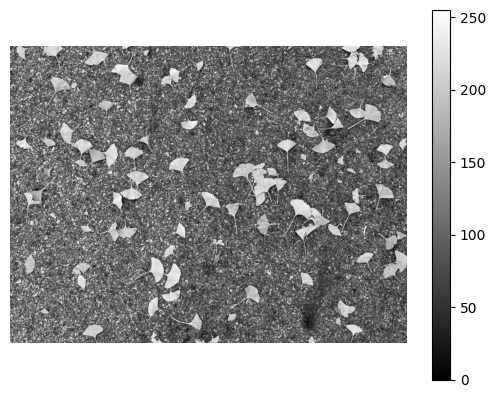

In [46]:
I = Image.open('leaf.jpg').convert('L')
f = np.array(I)[::2, ::2]
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

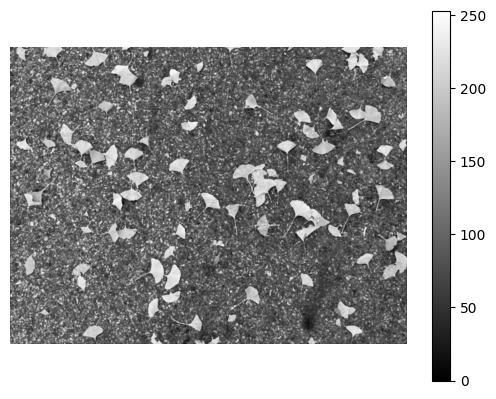

In [47]:
f_denoised = signal.medfilt2d(f,9)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

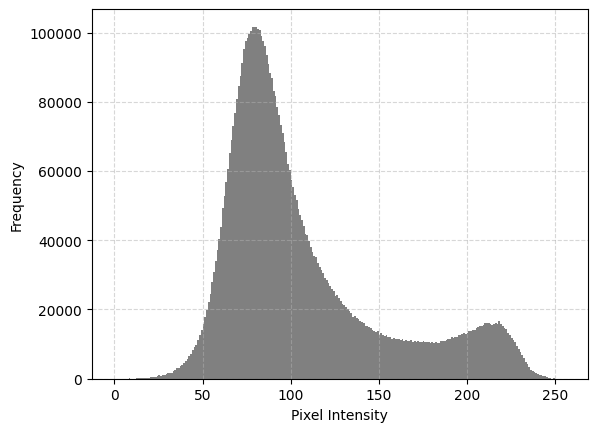

In [48]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

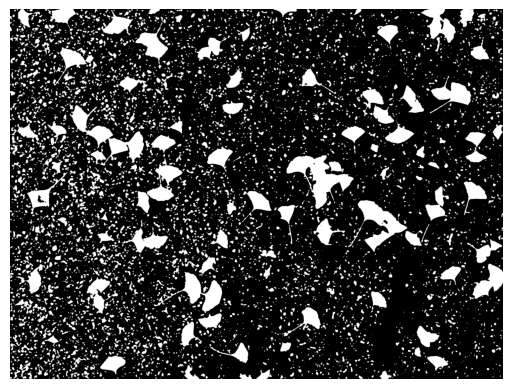

In [49]:
th_val = 140
f_mask = f_denoised > th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

검출된 영역의 개수: 97


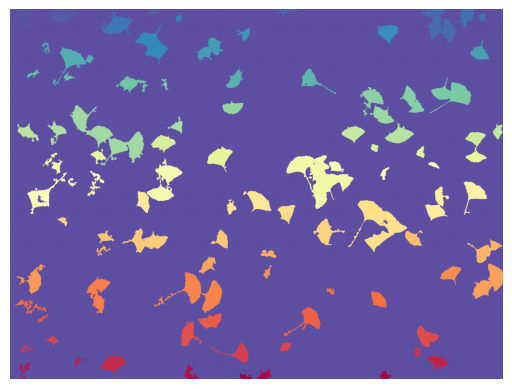

In [50]:
labels, nums = nd.label(f_mask)

sizes = np.bincount(labels.ravel()) #각 영역의 픽셀 수 계산
f_mask_clean = sizes[labels] >= 1000 #1000픽셀보다 작은 영역 삭제
f_mask_clean[labels == 0] = False #배경이 물체로 선택되지 않도록
labels, nums = nd.label(f_mask_clean) #작은 영역을 제거한 영상에서 다시 영역 찾기
print('검출된 영역의 개수:', nums)

plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [51]:
cc = np.zeros((nums-1,2))
for i in range(1,nums):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 4988
index: 2, number of pixels: 8738
index: 3, number of pixels: 1345
index: 4, number of pixels: 2418
index: 5, number of pixels: 18839
index: 6, number of pixels: 5839
index: 7, number of pixels: 12049
index: 8, number of pixels: 1142
index: 9, number of pixels: 1129
index: 10, number of pixels: 16259
index: 11, number of pixels: 8003
index: 12, number of pixels: 2693
index: 13, number of pixels: 9979
index: 14, number of pixels: 6016
index: 15, number of pixels: 1316
index: 16, number of pixels: 13142
index: 17, number of pixels: 5589
index: 18, number of pixels: 7148
index: 19, number of pixels: 1248
index: 20, number of pixels: 1262
index: 21, number of pixels: 7347
index: 22, number of pixels: 18912
index: 23, number of pixels: 1051
index: 24, number of pixels: 9405
index: 25, number of pixels: 8935
index: 26, number of pixels: 6021
index: 27, number of pixels: 7658
index: 28, number of pixels: 39199
index: 29, number of pixels: 3165
index: 30, number

## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [52]:
ind_max = np.argmax(cc[:,1])
print(f'the largest component: index {int(ind_max)}, # of pixels: {int(cc[ind_max,1])}')
ind_min = np.argmin(cc[:,1])
print(f'the smallest component: index {int(ind_min)}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 42, # of pixels: 44928
the smallest component: index 81, # of pixels: 1018


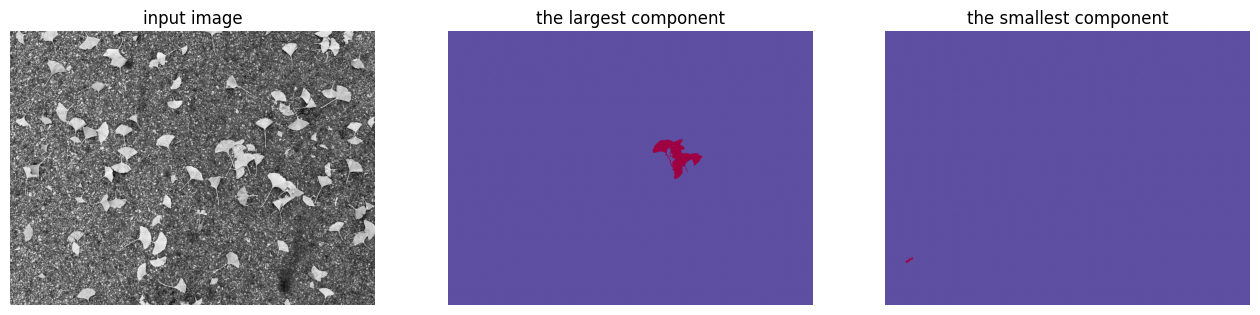

In [53]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==cc[ind_max,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the largest component')
plt.subplot(133)
plt.imshow(labels==cc[ind_min,0],cmap='Spectral_r')
plt.axis('off')
plt.title('the smallest component')
plt.show()